# Dependence-Robust Sharpe Comparisons

The influence value shows how one return contributes to the sampling error of a Sharpe estimate:

$$
z_t=\frac{r_t-\overline r}{s_r},
\qquad
IF_t=z_t-\frac{1}{2}\widehat{SR}(z_t^2-1).
$$

Here, $r_t$ is return $t$, $\overline r$ and $s_r$ are its sample mean and standard deviation, $z_t$ is the standardized return, $\widehat{SR}$ is the sample Sharpe ratio, and $IF_t$ is the corresponding influence value.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import hashlib
import math
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

from RiskLabAI.backtest.probabilistic_sharpe_ratio import benchmark_sharpe_ratio, probabilistic_sharpe_ratio
from RiskLabAI.backtest.sharpe_inference import lplz_sharpe_inference, newey_west_automatic_lag, newey_west_long_run_variance, sharpe_ratio_influence_function
from RiskLabAI.backtest.multiple_testing import benjamini_hochberg_yekutieli_adjusted_p_values, haircut_sharpe_ratios, holm_adjusted_p_values, sharpe_ratio_p_values
from RiskLabAI.backtest.test_set_overfitting import expected_max_sharpe_ratio, estimated_sharpe_ratio_z_statistics, strategy_type1_error_probability, strategy_type2_error_probability, theta_for_type2_error
from RiskLabAI.backtest.robust_statistics import sharpe_difference_test

DATA_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
DATA_DIR = ROOT / "data" / "public" / "fred"
DATA_PATH = ensure_dataset(ROOT, "fred_sp500")
EXPECTED_DATA_HASH = "2098B209EE3AFDB3B2C1E783AC90A2BB7DD3865FEB416D0FABEDBB4A7A542754"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
raw = pd.read_csv(DATA_PATH)
raw["observation_date"] = pd.to_datetime(raw["observation_date"])
prices = raw.set_index("observation_date")["SP500"].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()

fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [("Trend", 1.0), ("Reversal", -1.0)]:
            name = f"{orientation} {fast_window}/{slow_window}"
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({"Trial": len(catalog_rows) + 1, "Rule": orientation, "Fast span": fast_window, "Slow span": slow_window, "Name": name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)

FIGURES = ROOT / "outputs" / "figures" / "20_sharpe_multiple_testing"
TABLES = ROOT / "outputs" / "tables" / "20_sharpe_multiple_testing"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("-inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def period_sharpe(values):
    array = np.asarray(values, dtype=float)
    deviation = array.std(ddof=1)
    return float(array.mean() / deviation) if deviation > 0 else 0.0

def return_moments(values):
    array = np.asarray(values, dtype=float)
    return float(ss.skew(array, bias=False)), float(ss.kurtosis(array, fisher=False, bias=False))

def opposite_name(name):
    return name.replace("Trend", "Reversal") if name.startswith("Trend") else name.replace("Reversal", "Trend")

trial_sharpes = np.array([period_sharpe(performances[column]) for column in performances])
annual_sharpes = trial_sharpes * np.sqrt(252.0)
trial_mean = float(trial_sharpes.mean())
trial_spread = float(trial_sharpes.std(ddof=0))
trial_count = performances.shape[1]
observation_count = performances.shape[0]
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Single-Sharpe Inference with Serial Dependence

A Bartlett-weighted long-run variance adds sample autocovariances to the ordinary variance:

$$
\widehat\Omega_L=\widehat\gamma_0+2\sum_{\ell=1}^{L}\left(1-\frac{\ell}{L+1}\right)\widehat\gamma_\ell,
\qquad
\widehat{SE}_{HAC}(\widehat{SR})=\sqrt{\frac{\widehat\Omega_L}{T}}.
$$

Here, $\widehat\gamma_\ell$ is the sample autocovariance of the influence values at lag $\ell$, $L$ is the largest included lag, $\widehat\Omega_L$ is the estimated long-run variance, $T$ is the number of returns, and $\widehat{SE}_{HAC}$ is the resulting standard error of the Sharpe estimate.

,Trial,Name,Annual Sharpe,Lag-one return correlation,Automatic lag,Independent standard error,HAC standard error,HAC lower limit,HAC upper limit,HAC two-sided p-value
0,1,Trend 3/30,0.368432,-0.161666,7,0.346968,0.295543,-0.210821,0.947686,0.212534
1,2,Reversal 3/30,-0.368432,-0.161666,7,0.346968,0.295543,-0.947686,0.210821,0.212534
2,3,Trend 3/60,0.252547,-0.162639,7,0.347164,0.307401,-0.349947,0.855041,0.411330
3,4,Reversal 3/60,-0.252547,-0.162639,7,0.347164,0.307401,-0.855041,0.349947,0.411330
4,5,Trend 3/120,0.290021,-0.148358,7,0.347426,0.315692,-0.328724,0.908767,0.358261
5,6,Reversal 3/120,-0.290021,-0.148358,7,0.347426,0.315692,-0.908767,0.328724,0.358261
6,7,Trend 3/240,0.199220,-0.144621,7,0.347548,0.314509,-0.417205,0.815646,0.526451
7,8,Reversal 3/240,-0.199220,-0.144621,7,0.347548,0.314509,-0.815646,0.417205,0.526451
8,9,Trend 5/30,0.448622,-0.145134,7,0.346558,0.294945,-0.129459,1.026703,0.128250
9,10,Reversal 5/30,-0.448622,-0.145134,7,0.346558,0.294945,-1.026703,0.129459,0.128250


,Trial,Name,Annual Sharpe,Lag-one return correlation,Automatic lag,Independent standard error,HAC standard error,HAC lower limit,HAC upper limit,HAC two-sided p-value
8,9,Trend 5/30,0.448622,-0.145134,7,0.346558,0.294945,-0.129459,1.026703,0.128250
26,27,Trend 20/60,0.413375,-0.136726,7,0.347326,0.308618,-0.191504,1.018255,0.180427
12,13,Trend 5/120,0.370794,-0.148718,7,0.347533,0.310652,-0.238073,0.979660,0.232635
0,1,Trend 3/30,0.368432,-0.161666,7,0.346968,0.295543,-0.210821,0.947686,0.212534
20,21,Trend 10/120,0.356375,-0.142714,7,0.347313,0.308331,-0.247942,0.960692,0.247755
16,17,Trend 10/30,0.342441,-0.155509,7,0.346688,0.303342,-0.252098,0.936979,0.258943
4,5,Trend 3/120,0.290021,-0.148358,7,0.347426,0.315692,-0.328724,0.908767,0.358261
2,3,Trend 3/60,0.252547,-0.162639,7,0.347164,0.307401,-0.349947,0.855041,0.411330
14,15,Trend 5/240,0.250915,-0.167993,7,0.347450,0.303540,-0.344012,0.845841,0.408447
18,19,Trend 10/60,0.216851,-0.154427,7,0.347271,0.312870,-0.396364,0.830065,0.488246


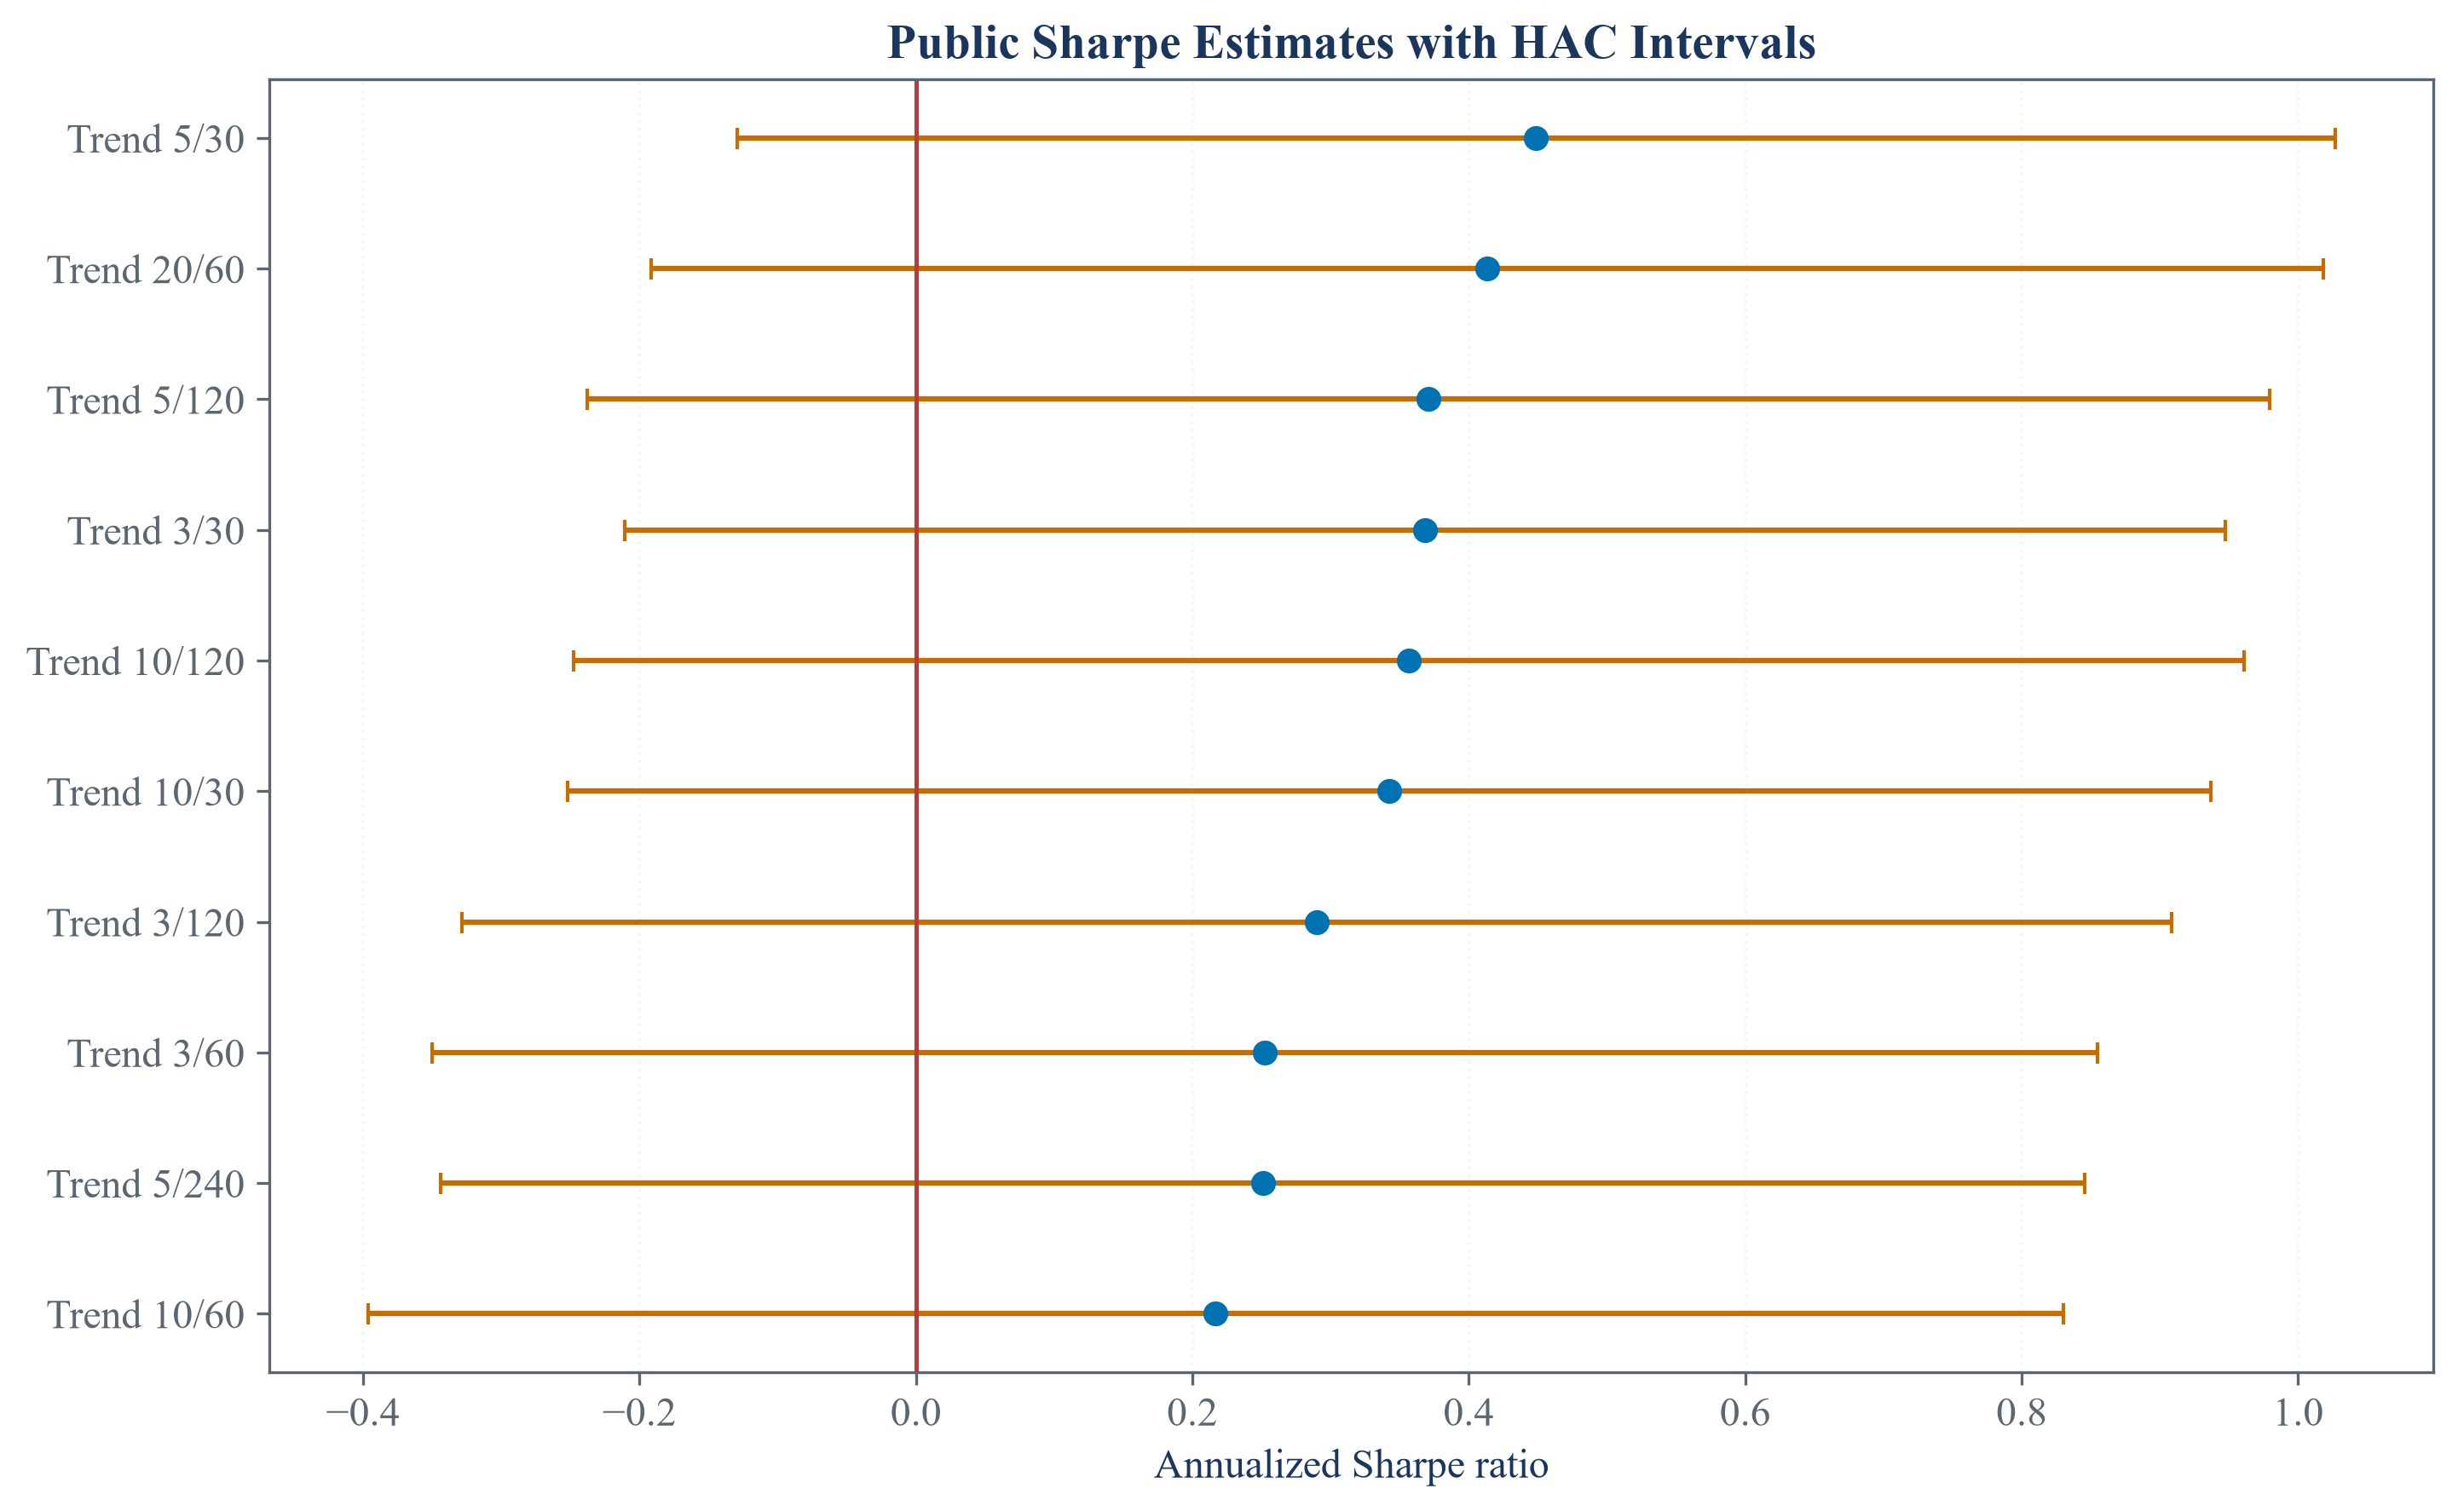

In [2]:
single_rows = []
for trial_number, name in enumerate(performances.columns, start=1):
    values = performances[name].to_numpy()
    sharpe = period_sharpe(values)
    skewness, kurtosis = return_moments(values)
    iid_variance = 1.0 - skewness * sharpe + (kurtosis - 1.0) * sharpe**2 / 4.0
    iid_standard_error = np.sqrt(max(iid_variance, 0.0) / (len(values) - 1))
    result = lplz_sharpe_inference(values)
    lag_one = pd.Series(values).autocorr(lag=1)
    single_rows.append({"Trial": trial_number, "Name": name, "Annual Sharpe": sharpe * np.sqrt(252.0), "Lag-one return correlation": lag_one, "Automatic lag": result["lag"], "Independent standard error": iid_standard_error * np.sqrt(252.0), "HAC standard error": result["standard_error"] * np.sqrt(252.0), "HAC lower limit": result["confidence_interval"][0] * np.sqrt(252.0), "HAC upper limit": result["confidence_interval"][1] * np.sqrt(252.0), "HAC two-sided p-value": result["p_value"]})
single_sharpe_inference = pd.DataFrame(single_rows)
leading_single_inference = single_sharpe_inference.sort_values(["Annual Sharpe", "Trial"], ascending=[False, True]).head(10)
save_table(single_sharpe_inference, "single_sharpe_inference", "Dependence-robust Sharpe inference for every public trial.", "tab:chapter18-single-sharpe-all")
save_table(leading_single_inference, "leading_single_inference", "Dependence-robust intervals for the ten largest public Sharpe estimates.", "tab:chapter18-leading-hac")
display(single_sharpe_inference)
display(leading_single_inference)

ordered = leading_single_inference.sort_values("Annual Sharpe")
lower_error = ordered["Annual Sharpe"] - ordered["HAC lower limit"]
upper_error = ordered["HAC upper limit"] - ordered["Annual Sharpe"]
figure, axis = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)
axis.errorbar(ordered["Annual Sharpe"], ordered["Name"], xerr=np.vstack([lower_error, upper_error]), fmt="o", color=palette["cyan"], ecolor=palette["amber"], capsize=3)
axis.axvline(0, color=palette["rose"], linewidth=1.2)
axis.set_title("Public Sharpe Estimates with HAC Intervals")
axis.set_xlabel("Annualized Sharpe ratio")
axis.grid(axis="x", alpha=0.28)
figure.savefig(FIGURES / "public_hac_intervals.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_hac_intervals.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_hac_intervals.png")))
plt.close(figure)

A paired comparison tests the difference between two Sharpe ratios with a standard error that preserves their joint time order:

$$
\widehat\Delta=\widehat{SR}_A-\widehat{SR}_B,
\qquad
Z_{HAC}=\frac{|\widehat\Delta|}{\widehat{SE}_{HAC}(\widehat\Delta)},
\qquad
\widehat p_{boot}=\frac{1+\sum_{b=1}^{B}\mathbf 1\{|Z_b^*|\geq Z_{HAC}\}}{B+1}.
$$

Here, $\widehat\Delta$ is the observed Sharpe difference, $\widehat{SE}_{HAC}(\widehat\Delta)$ is its long-run standard error, $Z_{HAC}$ is the absolute standardized difference, $B$ is the number of circular-block resamples, $Z_b^*$ is the centered studentized statistic in resample $b$, and $\widehat p_{boot}$ is the two-sided bootstrap p-value.

## Paired Public Comparisons

,First trial,Second trial,Annual Sharpe difference,Independent standard error,HAC standard error,Independent p-value,Block-bootstrap p-value,Independent rejection,Block-bootstrap rejection
0,Trend 5/30,Trend 20/60,0.035255,0.305745,0.267159,0.908202,0.9100,False,False
1,Trend 5/30,Reversal 5/30,0.897458,0.692949,0.567513,0.195276,0.1150,False,False
2,Trend 10/120,Reversal 10/120,0.712920,0.694459,0.599587,0.304616,0.2175,False,False


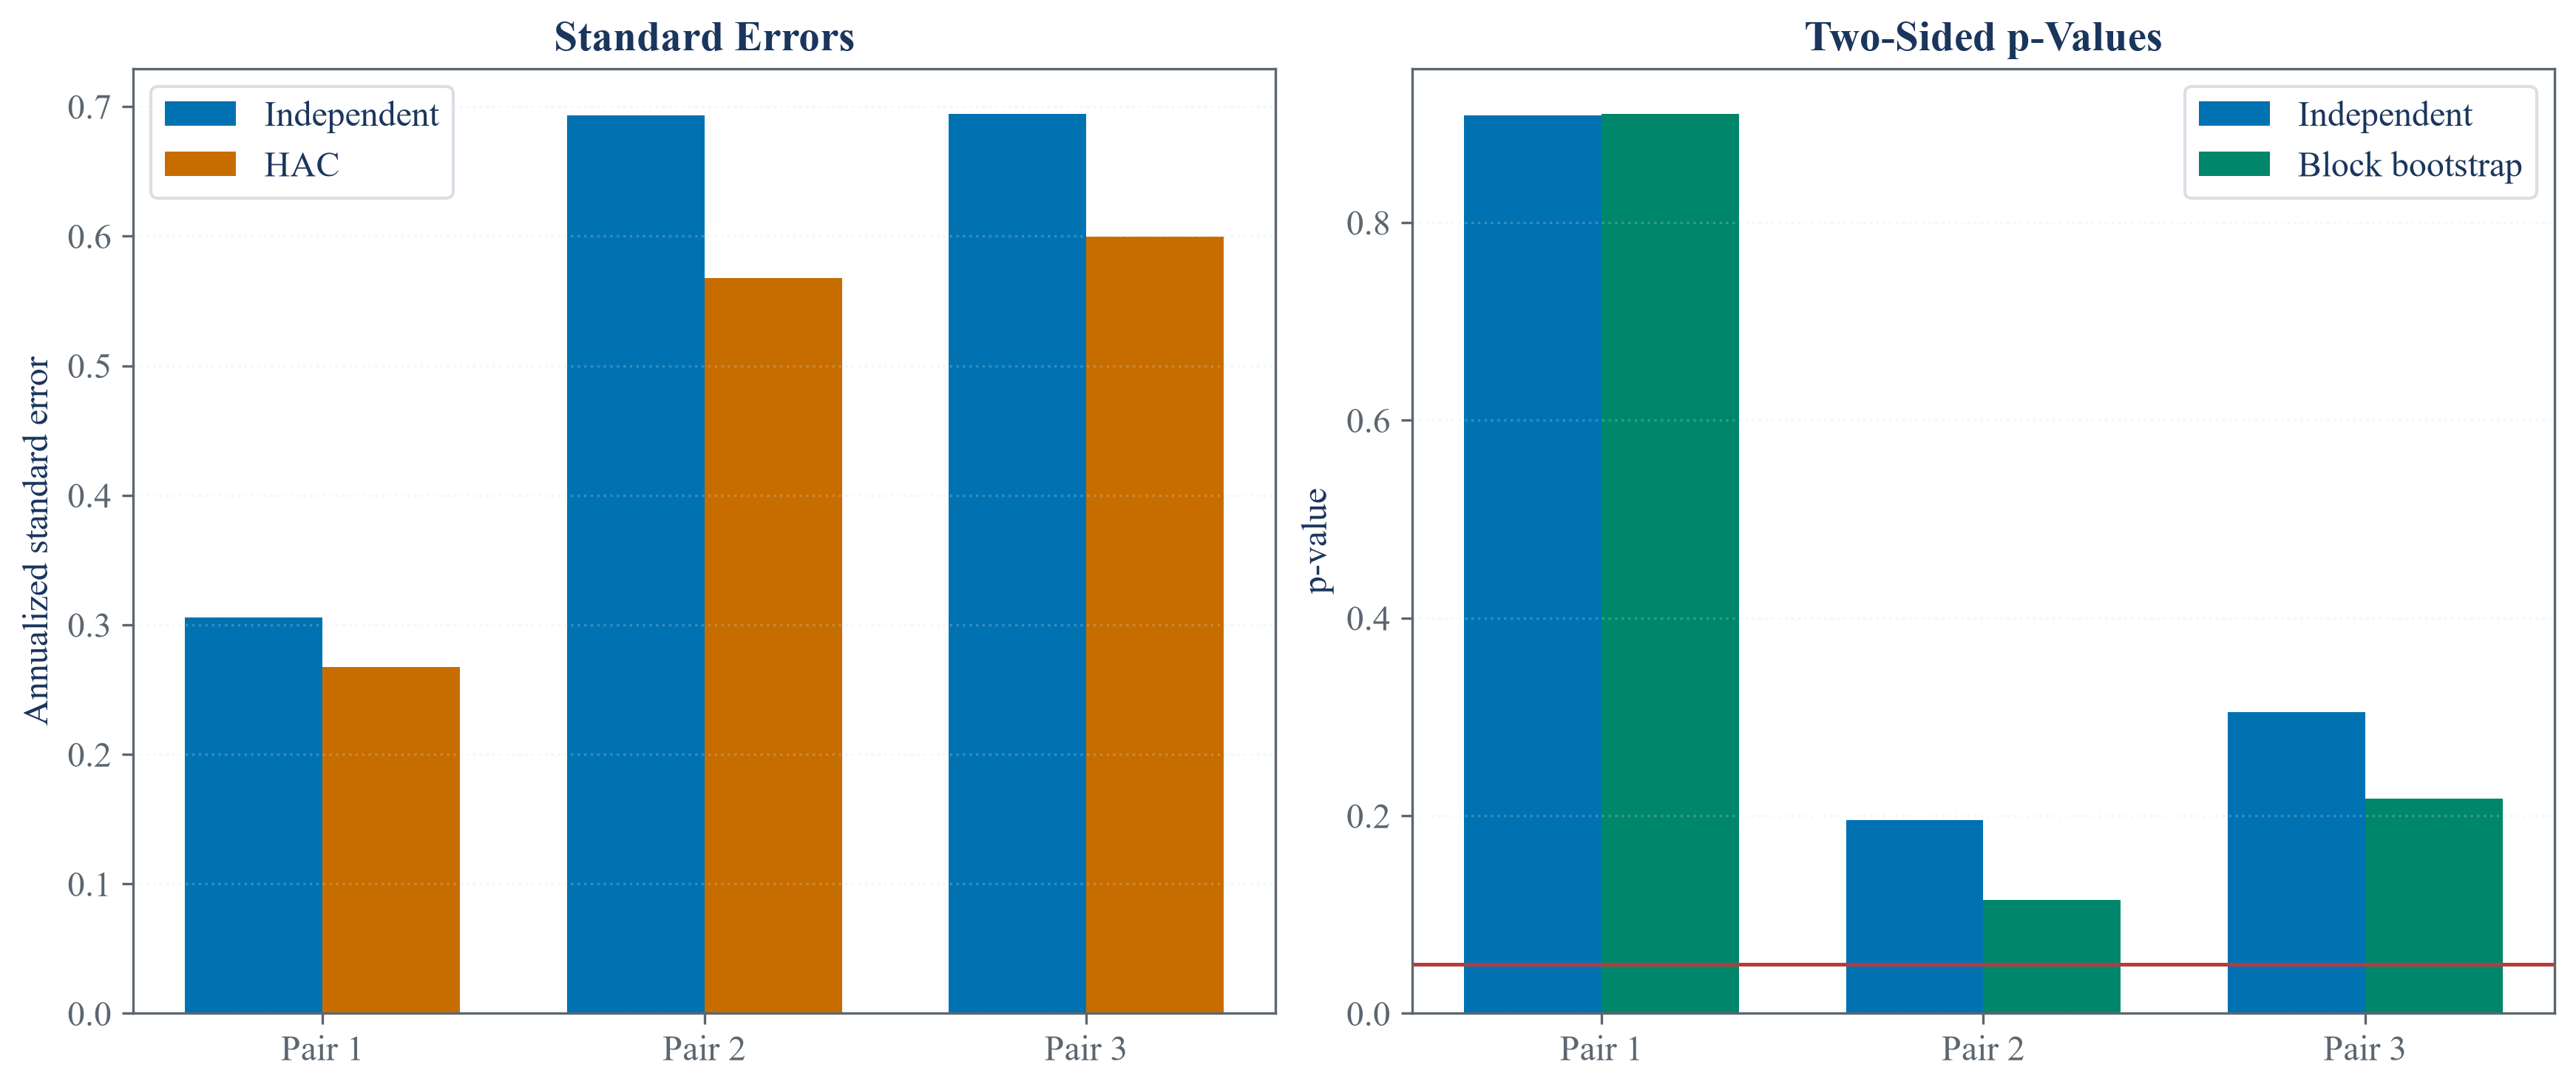

In [3]:
ranked_names = list(pd.Series(annual_sharpes, index=performances.columns).sort_values(ascending=False).index)
first_name = ranked_names[0]
second_name = ranked_names[1]
pair_names = [(first_name, second_name), (first_name, opposite_name(first_name)), ("Trend 10/120", "Reversal 10/120")]
comparison_rows = []
for pair_number, (name_a, name_b) in enumerate(pair_names, start=1):
    values_a = performances[name_a].to_numpy()
    values_b = performances[name_b].to_numpy()
    naive = sharpe_difference_test(values_a, values_b, method="naive")
    robust = sharpe_difference_test(values_a, values_b, method="ledoit_wolf", n_boot=399, random_state=1800 + pair_number)
    comparison_rows.append({"First trial": name_a, "Second trial": name_b, "Annual Sharpe difference": robust["delta"] * np.sqrt(252.0), "Independent standard error": naive["se"] * np.sqrt(252.0), "HAC standard error": robust["se"] * np.sqrt(252.0), "Independent p-value": naive["pvalue"], "Block-bootstrap p-value": robust["pvalue"], "Independent rejection": naive["reject"], "Block-bootstrap rejection": robust["reject"]})
public_sharpe_comparisons = pd.DataFrame(comparison_rows)
save_table(public_sharpe_comparisons, "public_sharpe_comparisons", "Paired public Sharpe comparisons before and after dependence correction.", "tab:chapter18-public-sharpe-comparisons")
display(public_sharpe_comparisons)

labels = [f"Pair {index}" for index in range(1, len(public_sharpe_comparisons) + 1)]
x = np.arange(len(labels))
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
axes[0].bar(x - 0.18, public_sharpe_comparisons["Independent standard error"], width=0.36, color=palette["cyan"], label="Independent")
axes[0].bar(x + 0.18, public_sharpe_comparisons["HAC standard error"], width=0.36, color=palette["amber"], label="HAC")
axes[0].set_xticks(x, labels)
axes[0].set_title("Standard Errors")
axes[0].set_ylabel("Annualized standard error")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(x - 0.18, public_sharpe_comparisons["Independent p-value"], width=0.36, color=palette["cyan"], label="Independent")
axes[1].bar(x + 0.18, public_sharpe_comparisons["Block-bootstrap p-value"], width=0.36, color=palette["green"], label="Block bootstrap")
axes[1].axhline(0.05, color=palette["rose"], linewidth=1.2)
axes[1].set_xticks(x, labels)
axes[1].set_title("Two-Sided p-Values")
axes[1].set_ylabel("p-value")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)
figure.savefig(FIGURES / "public_sharpe_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_sharpe_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_sharpe_comparison.png")))
plt.close(figure)

A controlled autoregressive return has a known zero mean and a chosen amount of serial dependence:

$$
r_t=\phi r_{t-1}+\varepsilon_t,
\qquad
\varepsilon_t\overset{iid}{\sim}\mathcal N(0,\sigma_\varepsilon^2).
$$

Here, $r_t$ is the return at time $t$, $\phi$ is the persistence parameter, $\varepsilon_t$ is an independent normal shock, $\sigma_\varepsilon$ is its standard deviation, and the true Sharpe ratio is zero because the process has zero unconditional mean.

## Controlled False-Positive Rates

,Calculation,Rejections,Simulations,False-positive rate
0,PSR with independent-return variance,46,300,0.153333
1,HAC influence-function inference,8,300,0.026667


,Persistence,Simulations,PSR false-positive rate,HAC false-positive rate
0,0,200,0.035,0.02
1,0.2,200,0.090,0.04
2,0.4,200,0.150,0.05
3,0.6,200,0.190,0.05


,Persistence,Simulations,Independent false-positive rate,Block-bootstrap false-positive rate
0,0,60,0.033333,0.050000
1,0.4,60,0.200000,0.016667


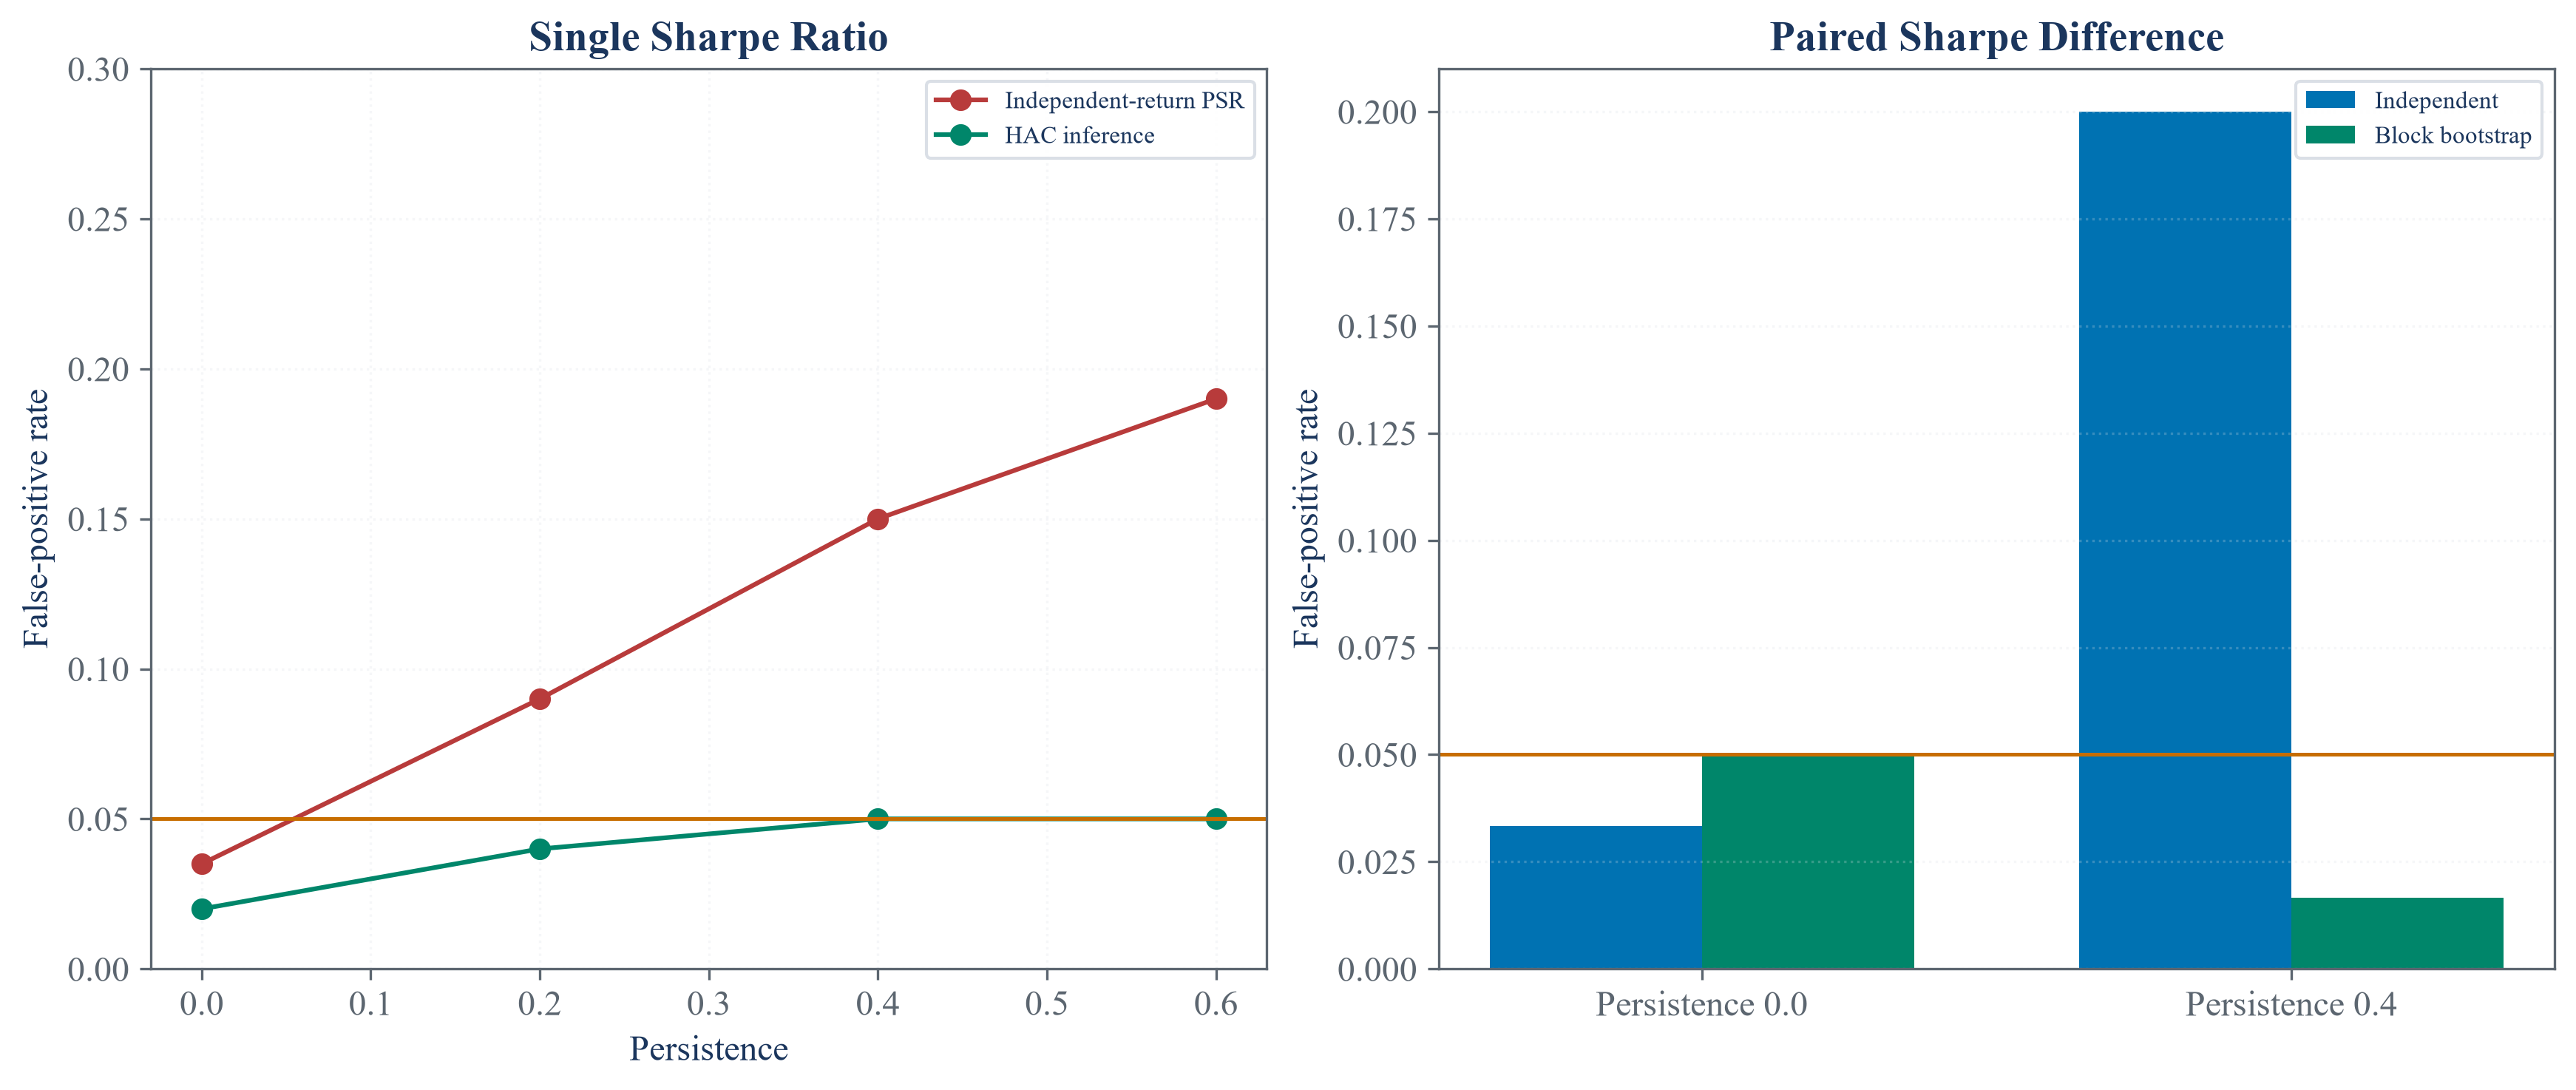

In [4]:
def ar1_returns(n_observations, persistence, seed, mean=0.0, shock_scale=0.01):
    rng = np.random.default_rng(seed)
    shocks = rng.standard_normal(n_observations) * shock_scale
    values = np.zeros(n_observations)
    for index in range(1, n_observations):
        values[index] = persistence * values[index - 1] + shocks[index]
    return values + mean

preliminary_counts = {"PSR": 0, "HAC": 0}
for seed in range(300):
    values = ar1_returns(500, 0.4, seed)
    sharpe = period_sharpe(values)
    skewness, kurtosis = return_moments(values)
    psr = probabilistic_sharpe_ratio(sharpe, 0.0, len(values), skewness, kurtosis)
    preliminary_counts["PSR"] += int(psr > 0.95)
    robust = lplz_sharpe_inference(values)
    preliminary_counts["HAC"] += int(robust["p_value"] < 0.05 and robust["sharpe_ratio"] > 0)
preliminary_ar1_reproduction = pd.DataFrame({"Calculation": ["PSR with independent-return variance", "HAC influence-function inference"], "Rejections": [preliminary_counts["PSR"], preliminary_counts["HAC"]], "Simulations": [300, 300], "False-positive rate": [preliminary_counts["PSR"] / 300, preliminary_counts["HAC"] / 300]})

false_positive_rows = []
for persistence in [0.0, 0.2, 0.4, 0.6]:
    psr_rejections = 0
    hac_rejections = 0
    for repetition in range(200):
        values = ar1_returns(500, persistence, 100000 + int(1000 * persistence) + repetition)
        sharpe = period_sharpe(values)
        skewness, kurtosis = return_moments(values)
        psr_rejections += int(probabilistic_sharpe_ratio(sharpe, 0.0, len(values), skewness, kurtosis) > 0.95)
        robust = lplz_sharpe_inference(values)
        hac_rejections += int(robust["p_value"] < 0.05 and robust["sharpe_ratio"] > 0)
    false_positive_rows.append({"Persistence": persistence, "Simulations": 200, "PSR false-positive rate": psr_rejections / 200, "HAC false-positive rate": hac_rejections / 200})
ar1_false_positive_summary = pd.DataFrame(false_positive_rows)

paired_rows = []
for persistence in [0.0, 0.4]:
    naive_rejections = 0
    robust_rejections = 0
    for repetition in range(60):
        rng = np.random.default_rng(300000 + int(1000 * persistence) + repetition)
        shocks = rng.standard_t(7, size=(240, 2)) * 0.01
        pairs = np.zeros((240, 2))
        for index in range(1, 240):
            pairs[index] = persistence * pairs[index - 1] + shocks[index]
        naive_rejections += int(sharpe_difference_test(pairs[:, 0], pairs[:, 1], method="naive")["reject"])
        robust_rejections += int(sharpe_difference_test(pairs[:, 0], pairs[:, 1], method="ledoit_wolf", n_boot=99, random_state=400000 + repetition)["reject"])
    paired_rows.append({"Persistence": persistence, "Simulations": 60, "Independent false-positive rate": naive_rejections / 60, "Block-bootstrap false-positive rate": robust_rejections / 60})
paired_null_summary = pd.DataFrame(paired_rows)

save_table(preliminary_ar1_reproduction, "preliminary_ar1_reproduction", "Reproduction of the preliminary autoregressive null experiment.", "tab:chapter18-preliminary-ar1", fit=False)
save_table(ar1_false_positive_summary, "ar1_false_positive_summary", "False-positive rates for single-Sharpe inference as persistence changes.", "tab:chapter18-ar1-false-positive")
save_table(paired_null_summary, "paired_null_summary", "False-positive rates for paired Sharpe comparisons under a known null.", "tab:chapter18-paired-null")
display(preliminary_ar1_reproduction)
display(ar1_false_positive_summary)
display(paired_null_summary)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
axes[0].plot(ar1_false_positive_summary["Persistence"], ar1_false_positive_summary["PSR false-positive rate"], marker="o", color=palette["rose"], label="Independent-return PSR")
axes[0].plot(ar1_false_positive_summary["Persistence"], ar1_false_positive_summary["HAC false-positive rate"], marker="o", color=palette["green"], label="HAC inference")
axes[0].axhline(0.05, color=palette["amber"], linewidth=1.2)
axes[0].set_title("Single Sharpe Ratio")
axes[0].set_xlabel("Persistence")
axes[0].set_ylabel("False-positive rate")
axes[0].set_ylim(0, max(0.3, ar1_false_positive_summary[["PSR false-positive rate", "HAC false-positive rate"]].to_numpy().max() + 0.03))
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)
pair_x = np.arange(len(paired_null_summary))
axes[1].bar(pair_x - 0.18, paired_null_summary["Independent false-positive rate"], width=0.36, color=palette["cyan"], label="Independent")
axes[1].bar(pair_x + 0.18, paired_null_summary["Block-bootstrap false-positive rate"], width=0.36, color=palette["green"], label="Block bootstrap")
axes[1].axhline(0.05, color=palette["amber"], linewidth=1.2)
axes[1].set_xticks(pair_x, [f"Persistence {value:.1f}" for value in paired_null_summary["Persistence"]])
axes[1].set_title("Paired Sharpe Difference")
axes[1].set_ylabel("False-positive rate")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.25)
figure.savefig(FIGURES / "dependence_false_positive_rates.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "dependence_false_positive_rates.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "dependence_false_positive_rates.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == EXPECTED_DATA_HASH
assert observation_count == 2090
assert trial_count == 32
assert single_sharpe_inference.shape == (32, 10)
assert leading_single_inference.shape == (10, 10)
assert single_sharpe_inference["Automatic lag"].eq(newey_west_automatic_lag(observation_count)).all()
assert single_sharpe_inference["HAC standard error"].gt(0).all()
assert single_sharpe_inference["HAC two-sided p-value"].between(0, 1).all()
assert public_sharpe_comparisons.shape == (3, 9)
assert public_sharpe_comparisons["Independent p-value"].between(0, 1).all()
assert public_sharpe_comparisons["Block-bootstrap p-value"].between(0, 1).all()
assert preliminary_counts == {"PSR": 46, "HAC": 8}
assert np.allclose(preliminary_ar1_reproduction["False-positive rate"], [46 / 300, 8 / 300])
assert ar1_false_positive_summary.shape == (4, 4)
assert ar1_false_positive_summary[["PSR false-positive rate", "HAC false-positive rate"]].apply(lambda column: column.between(0, 1).all()).all()
assert paired_null_summary.shape == (2, 4)
assert paired_null_summary[["Independent false-positive rate", "Block-bootstrap false-positive rate"]].apply(lambda column: column.between(0, 1).all()).all()
sample_values = ar1_returns(500, 0.4, 999)
influence = sharpe_ratio_influence_function(sample_values)
assert influence.shape == sample_values.shape
assert abs(influence.mean()) < 0.01
assert newey_west_long_run_variance(influence, newey_west_automatic_lag(len(influence))) > 0
assert (FIGURES / "public_hac_intervals.pdf").is_file()
assert (FIGURES / "public_sharpe_comparison.pdf").is_file()
assert (FIGURES / "dependence_false_positive_rates.pdf").is_file()
assert (TABLES / "single_sharpe_inference.tex").is_file()
assert (TABLES / "leading_single_inference.tex").is_file()
assert (TABLES / "public_sharpe_comparisons.tex").is_file()
assert (TABLES / "preliminary_ar1_reproduction.tex").is_file()
assert (TABLES / "ar1_false_positive_summary.tex").is_file()
assert (TABLES / "paired_null_summary.tex").is_file()